# Lab 03: Developing a Tiny Transformer Language Model

In [14]:
%pip install datasets torch matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load the dataset

In [15]:
import torch.nn as nn
from torch.nn import functional as F
from datasets import load_dataset

dataset = load_dataset("roneneldan/TinyStories")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 2119719
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 21990
    })
})


In [16]:
# look at a few stories
for i in range(3):
    print("Story", i + 1)
    print(dataset["train"][i]["text"])
    print("-" * 50)

Story 1
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.
--------------------------------------------------
Story 2
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park wh

In [17]:
# length and structure of the first 1000 stories
sample = dataset["train"][:1000]["text"]

char_lengths = [len(story) for story in sample]
word_lengths = [len(story.split()) for story in sample]

print("Average characters per story:", sum(char_lengths) / len(char_lengths))
print("Shortest:", min(char_lengths), "Longest:", max(char_lengths))
print("Average words per story:", sum(word_lengths) / len(word_lengths))

# how the stories usually start
print("Start with 'Once upon a time':", sum(story.startswith("Once upon a time") for story in sample))
print("Start with 'One day':", sum(story.startswith("One day") for story in sample))
print("Have dialogue in quotes:", sum('"' in story for story in sample))

Average characters per story: 941.64
Shortest: 274 Longest: 4123
Average words per story: 183.801
Start with 'Once upon a time': 539
Start with 'One day': 41
Have dialogue in quotes: 531


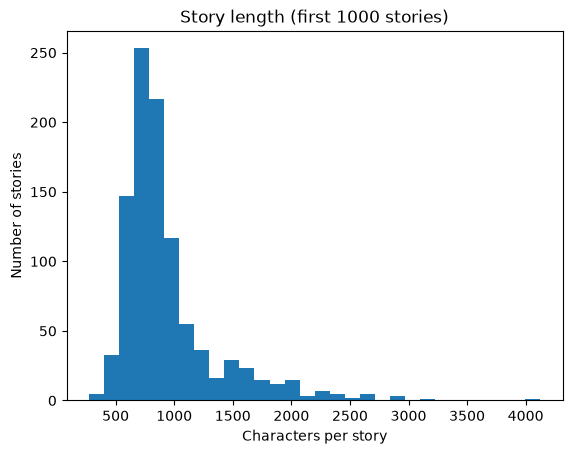

In [18]:
import matplotlib.pyplot as plt

plt.hist(char_lengths, bins=30)
plt.xlabel("Characters per story")
plt.ylabel("Number of stories")
plt.title("Story length (first 1000 stories)")
plt.show()

## 2. Preprocess the text

In [19]:
# the full train split has over 2 million stories, a small part is enough for a tiny model on a CPU
num_stories = 2000
stories = dataset["train"][:num_stories]["text"]
text = "\n\n".join(stories)

print("Stories used:", num_stories)
print("Total characters:", len(text))

Stories used: 2000
Total characters: 1704918


In [20]:
# some stories have broken characters like â € ™ (curly quotes saved with the wrong encoding)
odd_characters = [ch for ch in set(text) if ord(ch) > 127]
print("Non-ASCII characters:", odd_characters)
print("How many times they appear:", sum(text.count(ch) for ch in odd_characters))

# keep plain ASCII only, so these don't become tokens of their own
text = "".join(ch for ch in text if ord(ch) < 128)
print("Characters after cleaning:", len(text))

Non-ASCII characters: ['™', 'œ', '”', '¦', '“', 'â', '€', '˜']
How many times they appear: 2237
Characters after cleaning: 1702681


In [21]:
# character level tokenizer: every different character gets its own number
characters = sorted(set(text))
vocab_size = len(characters)

char_to_int = {ch: i for i, ch in enumerate(characters)}
int_to_char = {i: ch for i, ch in enumerate(characters)}

def encode(s):
    return [char_to_int[ch] for ch in s]

def decode(ids):
    return "".join(int_to_char[i] for i in ids)

print("Vocabulary size:", vocab_size)
print(characters)
print(encode("Once upon a time"))
print(decode(encode("Once upon a time")))

Vocabulary size: 72
['\n', ' ', '!', '"', '$', "'", ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '8', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
[34, 59, 48, 50, 1, 66, 61, 60, 59, 1, 46, 1, 65, 54, 58, 50]
Once upon a time


## 3. Prepare the training data

In [22]:
import torch

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

data = torch.tensor(encode(text), dtype=torch.long)

# first 90% for training, last 10% to check the model on text it hasn't trained on
split_index = int(0.9 * len(data))
train_data = data[:split_index]
val_data = data[split_index:]

print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

Device: cpu
Training characters: 1532412
Validation characters: 170269


In [23]:
block_size = 64   # how many characters the model looks at, at once
batch_size = 32

# the target is the input moved one character to the right
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(8):
    print("input:", repr(decode(x[:t + 1].tolist())), "-> target:", repr(int_to_char[y[t].item()]))

input: 'O' -> target: 'n'
input: 'On' -> target: 'e'
input: 'One' -> target: ' '
input: 'One ' -> target: 'd'
input: 'One d' -> target: 'a'
input: 'One da' -> target: 'y'
input: 'One day' -> target: ','
input: 'One day,' -> target: ' '


In [24]:
def get_batch(split):
    d = train_data if split == "train" else val_data
    starts = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in starts])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


## 4. Build the Transformer

In [25]:
dropout = 0.1

class Head(nn.Module):
    """one head of masked self-attention"""

    def __init__(self, n_embd, head_size, block_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # lower triangle of ones: each position can see itself and the ones before it
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        # scaled by 1/sqrt(head_size) so softmax doesn't get too sharp
        weights = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        weights = weights.masked_fill(self.tril[:T, :T] == 0, float("-inf"))  # hide future characters
        weights = F.softmax(weights, dim=-1)
        weights = self.dropout(weights)
        v = self.value(x)
        return weights @ v


class MultiHeadAttention(nn.Module):
    """several heads side by side, joined and mixed with a linear layer"""

    def __init__(self, n_embd, n_head, block_size):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList([Head(n_embd, head_size, block_size) for _ in range(n_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """attention then feed-forward, each with layer norm and a residual connection"""

    def __init__(self, n_embd, n_head, block_size):
        super().__init__()
        self.attention = MultiHeadAttention(n_embd, n_head, block_size)
        self.feed_forward = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))     # residual: add the input back on
        x = x + self.feed_forward(self.ln2(x))
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size) for _ in range(n_layer)])
        self.ln_final = nn.LayerNorm(n_embd)
        self.output_layer = nn.Linear(n_embd, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        tokens = self.token_embedding(idx)
        positions = self.position_embedding(torch.arange(T, device=idx.device))
        x = tokens + positions
        x = self.blocks(x)
        x = self.ln_final(x)
        return self.output_layer(x)   # a score for every character in the vocabulary

## 5. Initialise the model

In [26]:
import math

n_embd = 64
n_head = 4
n_layer = 2
learning_rate = 1e-3

torch.manual_seed(42)
model = TinyTransformer(vocab_size, n_embd, n_head, n_layer, block_size).to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# before training it is just guessing, so the loss should be close to ln(vocab_size)
xb, yb = get_batch("train")
logits = model(xb)
print("Output shape:", logits.shape)
print("Loss before training:", loss_function(logits.view(-1, vocab_size), yb.view(-1)).item())
print("ln(vocab_size):", math.log(vocab_size))

Parameters: 113096
Output shape: torch.Size([32, 64, 72])
Loss before training: 4.505015850067139
ln(vocab_size): 4.276666119016055


## 6. Train the model and 7. Monitor training

In [27]:
@torch.no_grad()
def estimate_loss(model, eval_batches=50):
    # average over many batches, one batch is too noisy
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(eval_batches):
            xb, yb = get_batch(split)
            logits = model(xb)
            losses.append(loss_function(logits.view(-1, vocab_size), yb.view(-1)).item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out


# one epoch = enough batches to go through the training characters about once
steps_per_epoch = len(train_data) // (batch_size * block_size)
print("Steps per epoch:", steps_per_epoch)


def train(model, optimizer, epochs):
    history = {"train": [], "val": []}
    for epoch in range(epochs):
        for step in range(steps_per_epoch):
            xb, yb = get_batch("train")
            logits = model(xb)                                          # predict the next characters
            loss = loss_function(logits.view(-1, vocab_size), yb.view(-1))
            optimizer.zero_grad()
            loss.backward()                                             # backpropagation
            optimizer.step()                                            # update the parameters

        losses = estimate_loss(model)
        history["train"].append(losses["train"])
        history["val"].append(losses["val"])
        print(f"Epoch {epoch + 1}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
    return history

Steps per epoch: 748


In [28]:
import time

epochs = 5
start = time.time()
history = train(model, optimizer, epochs)
print("Training time:", round(time.time() - start), "seconds")

Epoch 1: train loss 1.8808, val loss 1.9318
Epoch 2: train loss 1.6016, val loss 1.6523
Epoch 3: train loss 1.4822, val loss 1.5326
Epoch 4: train loss 1.4134, val loss 1.4675
Epoch 5: train loss 1.3816, val loss 1.4287
Training time: 415 seconds


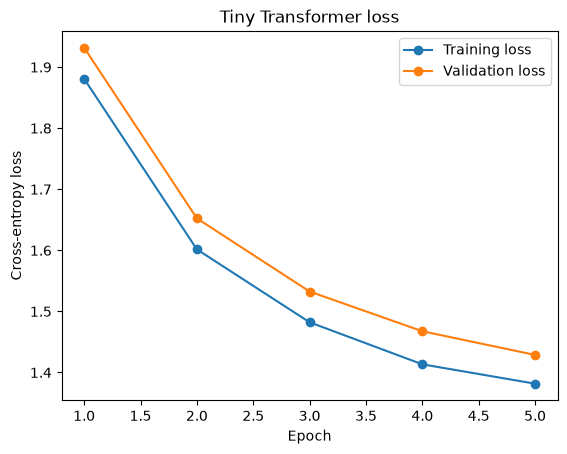

In [29]:
import os
os.makedirs("../results", exist_ok=True)

epoch_numbers = range(1, epochs + 1)
plt.plot(epoch_numbers, history["train"], marker="o", label="Training loss")
plt.plot(epoch_numbers, history["val"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer loss")
plt.legend()
plt.savefig("../results/loss_curve.png")
plt.show()

## 8. Evaluate the model

In [30]:
# more batches than during training, so the final number is steadier
final = estimate_loss(model, eval_batches=200)
print("Training loss:", final["train"])
print("Validation loss:", final["val"])
print("Perplexity:", math.exp(final["val"]))

Training loss: 1.3767498868703842
Validation loss: 1.4208107966184615
Perplexity: 4.1404761637353085


## 9. Generate stories

In [31]:
@torch.no_grad()
def generate(model, prompt, max_new_chars=300, temperature=0.8):
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(max_new_chars):
        idx_crop = idx[:, -block_size:]       # there are only block_size position embeddings
        logits = model(idx_crop)
        probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)   # scores for the next character only
        next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, next_id), dim=1)
    model.train()
    return decode(idx[0].tolist())


torch.manual_seed(42)
story = generate(model, "Once upon a time")
print(story)

Once upon a time was in the park. 

The was very save that was not to her worried whing the special down. All the bea. He familing to staror next his and stoon, the lack up. Once a time, there was a small other.

Tom didn't want to the storther each and excited ond the bround to play with her and sharted.

Once upo


In [32]:
# lower temperature = safer choices, higher = more random
for temperature in [0.5, 1.0]:
    torch.manual_seed(42)
    print("Temperature", temperature)
    print(generate(model, "Once upon a time", max_new_chars=200, temperature=temperature))
    print("-" * 50)

Temperature 0.5
Once upon a time the in the park. 

The was very save the boy and was and so girl was so happy for down and sure of the the big boy careful the show and he worder. He could playing the on, the ball park it to play wi
--------------------------------------------------
Temperature 1.0
Once upon a time little girl smile up up. It was saves that that ove there on it, we walked so feer down. All the man. Roved courful not worth the little girl toy. Annice his magh. She old from the party and said, Th
--------------------------------------------------


## 10. Experiment with model settings

In [ ]:
import pandas as pd

# each setting trains a new model from scratch for 1 epoch (same seed, same text), so they can be compared
# 1 epoch keeps the whole thing to a few minutes on a CPU
experiments = [
    {"n_layer": 1, "n_head": 4},
    {"n_layer": 2, "n_head": 4},
    {"n_layer": 4, "n_head": 4},
    {"n_layer": 2, "n_head": 1},
    {"n_layer": 2, "n_head": 8},
]
experiment_epochs = 1

results = []
for exp in experiments:
    print("Training", exp)
    torch.manual_seed(42)
    m = TinyTransformer(vocab_size, n_embd, exp["n_head"], exp["n_layer"], block_size).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=learning_rate)
    start = time.time()
    h = train(m, opt, experiment_epochs)
    torch.manual_seed(42)
    results.append({
        "n_layer": exp["n_layer"],
        "n_head": exp["n_head"],
        "parameters": sum(p.numel() for p in m.parameters()),
        "val_loss": round(h["val"][-1], 4),
        "perplexity": round(math.exp(h["val"][-1]), 2),
        "seconds": round(time.time() - start),
        "sample": generate(m, "Once upon a time", max_new_chars=120),
    })

results_table = pd.DataFrame(results)
results_table.to_csv("../results/experiments.csv", index=False)
results_table[["n_layer", "n_head", "parameters", "val_loss", "perplexity", "seconds"]]

Training {'n_layer': 1, 'n_head': 4}


In [ ]:
# the text each setting wrote
for r in results:
    print(f"{r['n_layer']} layers, {r['n_head']} heads:")
    print(r["sample"])
    print("-" * 50)